In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.land

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
import sys

In [13]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [14]:
from functions import preproc_funcs as funcs

In [15]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    
]

In [16]:
model_list_alt = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CESM2', # ssp3
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'E3SM-1-0', # ssp3
    'E3SMv2', # ssp3
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    'UKESM1-0-LL', # ssp3
]

In [178]:
model = model_list_alt[14]
model

IndexError: list index out of range

In [161]:
ts_ssp5 = xr.open_dataset(f'/g/data/if69/as8561/data/enso_tele_robustness/smiles/{model}_ts.nc')
ts_ssp5_anom = funcs.calc_anom_annual(ts_ssp5, ts_ssp5.sel(time = slice('1960', '1990'))).tas

pr_ssp5 = xr.open_dataset(f'/g/data/if69/as8561/data/enso_tele_robustness/smiles/{model}_pr.nc')
pr_ssp5_anom = funcs.calc_anom_annual(pr_ssp5, pr_ssp5.sel(time = slice('1960', '1990'))).pr

In [162]:
ts_ssp5_anom

<xarray.DataArray 'tas' (model: 16, time: 252, lat: 72, lon: 144)> Size: 334MB
array([[[[ 1.48144555e+00,  1.49782438e+00,  1.50577390e+00, ...,
           1.44827280e+00,  1.45816195e+00,  1.47050794e+00],
         [ 1.85659253e+00,  1.90451940e+00,  1.93583255e+00, ...,
           1.71081639e+00,  1.77941884e+00,  1.81564174e+00],
         [ 2.10492417e+00,  2.15902491e+00,  2.23177812e+00, ...,
           1.88483587e+00,  1.96752759e+00,  2.03610176e+00],
         ...,
         [-4.15023124e+00, -4.06938104e+00, -3.99634798e+00, ...,
          -4.53665642e+00, -4.40605153e+00, -4.28560165e+00],
         [-4.98739794e+00, -4.91121371e+00, -4.83443144e+00, ...,
          -5.25766747e+00, -5.17440521e+00, -5.08410705e+00],
         [-5.61296688e+00, -5.57931748e+00, -5.54784163e+00, ...,
          -5.71563177e+00, -5.68215722e+00, -5.65326389e+00]],

        [[ 1.02714814e-01,  1.07375778e-01,  1.15426619e-01, ...,
           8.83988980e-02,  9.12259768e-02,  9.27160290e-02],
         [ 1.32909906e-01,  1.62809519e-01,  1.93675763e-01, ...,
           5.79533691e-02,  8.00281402e-02,  1.04916934e-01],
         [ 8.63540612e-02,  1.10741898e-01,  1.52228880e-01, ...,
          -4.72535318e-02,  5.27073748e-03,  5.14282070e-02],
...
         [ 2.26621126e+01,  2.26800018e+01,  2.27057610e+01, ...,
           2.26515376e+01,  2.26556331e+01,  2.26635306e+01],
         [ 2.37546692e+01,  2.37988925e+01,  2.38444283e+01, ...,
           2.36426090e+01,  2.36713713e+01,  2.37037758e+01],
         [ 2.46217755e+01,  2.46503557e+01,  2.46821612e+01, ...,
           2.45269844e+01,  2.45585096e+01,  2.45885009e+01]],

        [[ 3.96377437e+00,  3.96001092e+00,  3.96272419e+00, ...,
           3.97109537e+00,  3.97294571e+00,  3.96984735e+00],
         [ 3.97000726e+00,  3.98244441e+00,  3.98076405e+00, ...,
           3.93855352e+00,  3.94826122e+00,  3.96370832e+00],
         [ 3.82918757e+00,  3.84718846e+00,  3.86713597e+00, ...,
           3.72970386e+00,  3.76776663e+00,  3.79085867e+00],
         ...,
         [ 2.56986041e+01,  2.56996920e+01,  2.57068248e+01, ...,
           2.58784715e+01,  2.57951990e+01,  2.57357483e+01],
         [ 2.68349213e+01,  2.68409087e+01,  2.68516569e+01, ...,
           2.68249531e+01,  2.68248338e+01,  2.68292419e+01],
         [ 2.74872992e+01,  2.74984568e+01,  2.75109586e+01, ...,
           2.74562192e+01,  2.74656307e+01,  2.74760295e+01]]]])
Coordinates:
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
    height   float64 8B 1.5
  * model    (model) int64 128B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
  * time     (time) object 2kB 1849-06-01 00:00:00 ... 2100-06-01 00:00:00

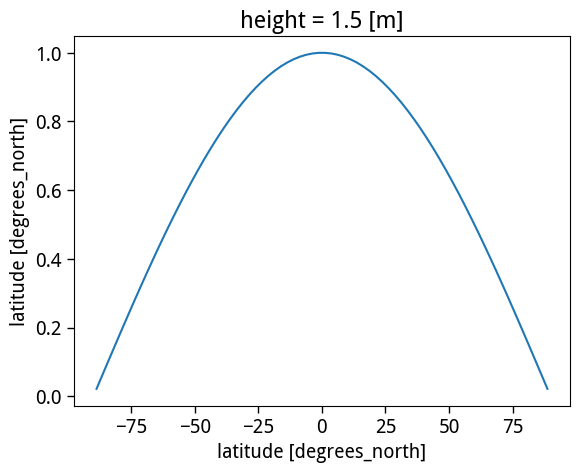

In [163]:
model_weights = np.cos(np.deg2rad(ts_ssp5_anom.lat))
model_weights.name = 'weights'
model_weights.plot()

In [164]:
ts_ssp5_det = funcs.detrend_rolling_window(ts_ssp5_anom, window_size=15)
pr_ssp5_det = funcs.detrend_rolling_window(pr_ssp5_anom, window_size=15)

In [165]:
nino34_ssp5 = ts_ssp5_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(model_weights).mean(('lat', 'lon'))
pr_ssp5_std = pr_ssp5_det/pr_ssp5_det.std('time')

In [166]:
gmst_ssp5 = ts_ssp5_anom.weighted(model_weights).mean(('lat', 'lon'))

In [149]:
# gmst_ssp5.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/smiles/{model}_gmst.nc')

### epoch division (only 8.5 W/m2 scenarios selected)

In [25]:
# out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), ts_ssp5_det.sel(time = slice('1950', '2014')), dim='time')
out_baseline

(<xarray.DataArray 'tas' (model: 16, lat: 72, lon: 144)> Size: 1MB
 array([[[ 0.39391375,  0.39464591,  0.395054  , ...,  0.39063736,
           0.39196928,  0.39313334],
         [ 0.43387071,  0.43337992,  0.43334676, ...,  0.42824249,
           0.43079432,  0.43206954],
         [ 0.45501679,  0.45918256,  0.46482439, ...,  0.43457804,
           0.44209193,  0.44928934],
         ...,
         [-0.15262907, -0.14748977, -0.14020189, ..., -0.164164  ,
          -0.16165202, -0.15841402],
         [-0.07292112, -0.0743328 , -0.0744848 , ..., -0.06835929,
          -0.06888687, -0.07053482],
         [-0.00656732, -0.00631275, -0.00465724, ..., -0.00611921,
          -0.00744058, -0.00732592]],
 
        [[-0.05829738, -0.05815739, -0.05733293, ..., -0.05988248,
          -0.06008019, -0.06005261],
         [ 0.02216729,  0.02170421,  0.02120115, ...,  0.0172337 ,
           0.01957184,  0.02111034],
         [ 0.09606118,  0.0948848 ,  0.09446484, ...,  0.09097142,
           0.0924

In [26]:
regr_baseline = xr.merge([out_baseline[0].to_dataset(name='regr'), out_baseline[1].to_dataset(name='corr'), out_baseline[2].to_dataset(name='pval')])

In [27]:
# # out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), pr_ssp5_std.sel(time = slice('2070', '2100')), dim='time')
# out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), ts_ssp5_det.sel(time = slice('2070', '2100')), dim='time')

In [28]:
# regr_end_century = xr.merge([out_end_century[0].to_dataset(name='regr'), out_end_century[1].to_dataset(name='corr'), out_end_century[2].to_dataset(name='pval')])

In [29]:
# # out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), pr_ssp5_std.sel(time = slice('2030', '2060')), dim='time')
# out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), ts_ssp5_det.sel(time = slice('2030', '2060')), dim='time')

In [30]:
# regr_mid_century = xr.merge([out_mid_century[0].to_dataset(name='regr'), out_mid_century[1].to_dataset(name='corr'), out_mid_century[2].to_dataset(name='pval')])

In [31]:
regr_baseline.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_baseline.nc')
# regr_end_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_end_century.nc')
# regr_mid_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_mid_century.nc')

In [32]:
# out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('1950', '2014')), pr_ssp5_std.sel(time = slice('1950', '2014')), dim='time')
out_baseline

(<xarray.DataArray (model: 16, lat: 72, lon: 144)> Size: 1MB
 array([[[ 0.16914979,  0.16899618,  0.16668189, ...,  0.16112472,
           0.15927345,  0.16719638],
         [ 0.18017262,  0.18064079,  0.19796771, ...,  0.19114456,
           0.20214149,  0.1912264 ],
         [ 0.19529794,  0.18684618,  0.18405506, ...,  0.19197186,
           0.1944852 ,  0.19219698],
         ...,
         [-0.35799223, -0.34450644, -0.32042354, ..., -0.31802565,
          -0.32201398, -0.34810325],
         [-0.1189131 , -0.10601786, -0.09908408, ..., -0.12293541,
          -0.10746541, -0.11032589],
         [ 0.15839608,  0.16141115,  0.16678679, ...,  0.15279856,
           0.15354176,  0.15428293]],
 
        [[-0.10938357, -0.11246949, -0.11339801, ..., -0.11550911,
          -0.11072328, -0.11021426],
         [ 0.03702113,  0.04614994,  0.0404296 , ...,  0.02170376,
           0.03381353,  0.04058847],
         [ 0.09822391,  0.12440411,  0.13533014, ...,  0.08415569,
           0.10388322, 

In [33]:
regr_baseline = xr.merge([out_baseline[0].to_dataset(name='regr'), out_baseline[1].to_dataset(name='corr'), out_baseline[2].to_dataset(name='pval')])

In [34]:
# # out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), pr_ssp5_std.sel(time = slice('2070', '2100')), dim='time')
# out_end_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2070', '2100')), ts_ssp5_det.sel(time = slice('2070', '2100')), dim='time')

In [35]:
# regr_end_century = xr.merge([out_end_century[0].to_dataset(name='regr'), out_end_century[1].to_dataset(name='corr'), out_end_century[2].to_dataset(name='pval')])

In [36]:
# # out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), pr_ssp5_std.sel(time = slice('2030', '2060')), dim='time')
# out_mid_century = funcs.get_all_metrics(nino34_ssp5.sel(time = slice('2030', '2060')), ts_ssp5_det.sel(time = slice('2030', '2060')), dim='time')

In [37]:
# regr_mid_century = xr.merge([out_mid_century[0].to_dataset(name='regr'), out_mid_century[1].to_dataset(name='corr'), out_mid_century[2].to_dataset(name='pval')])

In [38]:
regr_baseline.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc')
# regr_end_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_end_century.nc')
# regr_mid_century.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr_mid_century.nc')

### GWL division (all models)

In [ ]:
# out15 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), ts_ssp5_det.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), dim='time')
# regr15 = xr.merge([out15[0].to_dataset(name='regr'), out15[1].to_dataset(name='corr'), out15[2].to_dataset(name='pval')])

In [ ]:
# out20 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), ts_ssp5_det.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), dim='time')
# regr20 = xr.merge([out20[0].to_dataset(name='regr'), out20[1].to_dataset(name='corr'), out20[2].to_dataset(name='pval')])

In [167]:
out30 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), ts_ssp5_det.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), dim='time')
regr30 = xr.merge([out30[0].to_dataset(name='regr'), out30[1].to_dataset(name='corr'), out30[2].to_dataset(name='pval')])

In [168]:
out40 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), ts_ssp5_det.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), dim='time')
regr40 = xr.merge([out40[0].to_dataset(name='regr'), out40[1].to_dataset(name='corr'), out40[2].to_dataset(name='pval')])

In [169]:
out50 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), ts_ssp5_det.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), dim='time')
regr50 = xr.merge([out50[0].to_dataset(name='regr'), out50[1].to_dataset(name='corr'), out50[2].to_dataset(name='pval')])

In [171]:
# regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
# regr15.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr15.nc')
# regr20.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr20.nc')
regr30.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr30.nc')
regr40.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr40.nc')
regr50.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts/{model}_regr50.nc')

In [172]:
# out15 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), pr_ssp5_std.where((gmst_ssp5 > 1.4) & (gmst_ssp5 < 1.6)), dim='time')
# regr15 = xr.merge([out15[0].to_dataset(name='regr'), out15[1].to_dataset(name='corr'), out15[2].to_dataset(name='pval')])

In [173]:
# out20 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), pr_ssp5_std.where((gmst_ssp5 > 1.9) & (gmst_ssp5 < 2.1)), dim='time')
# regr20 = xr.merge([out20[0].to_dataset(name='regr'), out20[1].to_dataset(name='corr'), out20[2].to_dataset(name='pval')])

In [174]:
out30 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), pr_ssp5_std.where((gmst_ssp5 > 2.9) & (gmst_ssp5 < 3.1)), dim='time')
regr30 = xr.merge([out30[0].to_dataset(name='regr'), out30[1].to_dataset(name='corr'), out30[2].to_dataset(name='pval')])

In [175]:
out40 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), pr_ssp5_std.where((gmst_ssp5 > 3.9) & (gmst_ssp5 < 4.1)), dim='time')
regr40 = xr.merge([out40[0].to_dataset(name='regr'), out40[1].to_dataset(name='corr'), out40[2].to_dataset(name='pval')])

In [176]:
out50 = funcs.get_all_metrics(nino34_ssp5.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), pr_ssp5_std.where((gmst_ssp5 > 4.9) & (gmst_ssp5 < 5.1)), dim='time')
regr50 = xr.merge([out50[0].to_dataset(name='regr'), out50[1].to_dataset(name='corr'), out50[2].to_dataset(name='pval')])

In [177]:
# regr_baseline.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
# regr15.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr15.nc')
# regr20.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr20.nc')
regr30.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr30.nc')
regr40.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr40.nc')
regr50.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr50.nc')

### composites

In [25]:
en_composite = ts_ssp5_det.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
ln_composite = ts_ssp5_det.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
neut_composite = ts_ssp5_det.where((nino34_ssp5 > -0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')) & (nino34_ssp5 < 0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')))

In [26]:
composites = xr.merge([en_composite.to_dataset(name='en'), ln_composite.to_dataset(name = 'ln'), neut_composite.to_dataset(name='neut')])

In [27]:
composites.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/ts_enso_comp/{model}_composites.nc')

In [28]:
en_composite = pr_ssp5_std.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
ln_composite = pr_ssp5_std.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1950', '2014')).std('time'))
neut_composite = pr_ssp5_std.where((nino34_ssp5 > -0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')) & (nino34_ssp5 < 0.5*nino34_ssp5.sel(time = slice('1950', '2014')).std('time')))

In [29]:
composites = xr.merge([en_composite.to_dataset(name='en'), ln_composite.to_dataset(name = 'ln'), neut_composite.to_dataset(name='neut')])

In [30]:
composites.to_netcdf(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr_enso_comp/{model}_composites.nc')

In [ ]:
# en_composite = pr_ssp5_std.where(nino34_ssp5 > nino34_ssp5.sel(time = slice('1850', '1950')).std('time'))
# ln_composite = pr_ssp5_std.where(nino34_ssp5 < -nino34_ssp5.sel(time = slice('1850', '1950')).std('time'))

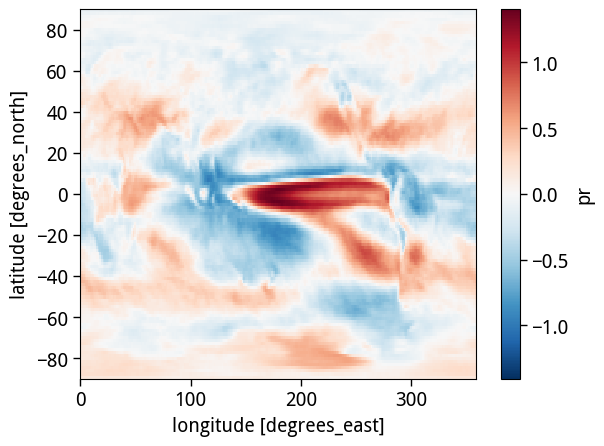

In [ ]:
# en_composite.sel(time = slice('1900', '1930')).mean('time').mean('model').plot()